In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 06 · Optimización con seguimiento (tracking)

Buscar mejores hiperparámetros es probar muchas configuraciones. Sin registro, a la mitad ya no sabes cuál era la buena:
por eso cada ensayo queda en **MLflow** con sus parámetros, métricas y etiquetas. Tres cuidados:

1. Se optimizan **solo los finalistas** del torneo (`reports/05_torneo.md`): HistGradientBoosting y XGBoost.
2. El **espacio de búsqueda** lleva lo que sabemos de cada algoritmo, y el **presupuesto** de ensayos se fijó antes
   (`especificaciones/06-optimizacion.md`, aprobada por el grupo el 5 nov 2026).
3. La mejor puntuación de una búsqueda es **optimista**: se **comprueba** en sedes que la búsqueda no vio.

Es **regresión**: se minimiza el **MAE** (puntos de error) con validación agrupada por sede. No hay probabilidades, costos
ni regla de decisión. La prueba (`test.joblib`) **no se abre**: se usa solo en la etapa 7.

In [2]:
import json
import time

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import optuna
import pandas as pd

from proyecto.data.split import GROUP_COL, assert_disjoint_groups, group_cv
from proyecto.models.train import TARGET, feature_frame, regression_metrics
from proyecto.models.tuning import (
    MODELS, STARTING_PARAMS, bootstrap_mae_difference, bootstrap_metric_ci, build_tuned_pipeline, reserve_groups, tune,
)
from proyecto.tracking.mlflow_utils import configure_mlflow, set_experiment

ROOT = Path.cwd().resolve().parent
REPORTS_DIR = ROOT / "reports"

with warnings.catch_warnings(record=True) as caught:   # mostramos por qué se usó (o no) Databricks
    warnings.simplefilter("always")
    where = configure_mlflow()
for w in caught:
    if "Databricks" in str(w.message):
        print("Aviso:", w.message)
experiment = set_experiment("saber11-optimizacion")
# En Databricks la ruta completa incluye la carpeta del usuario (su correo): no se imprime ni se guarda (repo público).
experiment_label = experiment.rsplit("/", 1)[-1]
print("MLflow:", where)
print("Experimento:", experiment_label, "(en Databricks, dentro de la carpeta del usuario)" if where.startswith("databricks") else "")
if where == "local":
    print("⚠ Databricks no está disponible en este equipo: se usa el respaldo local (mlflow_local.db).")

MLflow: databricks (token)
Experimento: saber11-optimizacion (en Databricks, dentro de la carpeta del usuario)


> **Si ves `local`:** no hubo conexión con Databricks (sin red, perfil sin configurar o cuota agotada). El notebook funciona
> igual y guarda todo en `mlflow_local.db` (raíz del repo, ignorado por Git). Para verlo:
> `mlflow ui --backend-store-uri sqlite:///mlflow_local.db`.

## 0. Datos de entrenamiento

Solo `train.joblib`. `test.joblib` sigue cerrado.

In [3]:
train = joblib.load(ROOT / "data" / "processed" / "train.joblib")
print(f"entrenamiento: {len(train):,} estudiantes · {train[GROUP_COL].nunique():,} sedes · objetivo: {TARGET}")

entrenamiento: 57,286 estudiantes · 1,155 sedes · objetivo: punt_global


## 1. Reservar sedes que la búsqueda no verá

Del entrenamiento separamos el **25 % de las sedes** (semilla 7, con `split_by_group`): la búsqueda trabaja solo con el
75 % restante. Así la comparación final se hace con colegios que ninguna configuración vio, como pasará en la app.

In [4]:
search_df, reserved_df = reserve_groups(train, frac=0.25, seed=7)
assert_disjoint_groups(search_df, reserved_df)   # falla si alguna sede está en los dos lados
shared = set(search_df[GROUP_COL]) & set(reserved_df[GROUP_COL])
print(f"búsqueda: {len(search_df):,} estudiantes · {search_df[GROUP_COL].nunique():,} sedes")
print(f"reserva:  {len(reserved_df):,} estudiantes · {reserved_df[GROUP_COL].nunique():,} sedes")
print("sedes compartidas:", len(shared))

X_search, y_search = feature_frame(search_df)
X_res, y_res = feature_frame(reserved_df)
cv = group_cv(3)   # 3 pliegues por sede, los mismos para todos los ensayos y para la medición de partida
folds = list(cv.split(X_search, y_search, groups=X_search[GROUP_COL]))
for i, (tr, va) in enumerate(folds):
    assert set(X_search[GROUP_COL].iloc[tr]).isdisjoint(set(X_search[GROUP_COL].iloc[va]))
    print(f"pliegue {i}: {len(tr):,} para ajustar · {len(va):,} para validar")

búsqueda: 43,805 estudiantes · 866 sedes


reserva:  13,481 estudiantes · 289 sedes
sedes compartidas: 0
pliegue 0: 29,203 para ajustar · 14,602 para validar
pliegue 1: 29,203 para ajustar · 14,602 para validar
pliegue 2: 29,204 para ajustar · 14,601 para validar


## 2. Reglas de decisión (escritas ANTES de ver los resultados)

Aprobadas por el grupo el 5 nov 2026 (`especificaciones/06-optimizacion.md` §6):

- **Regla 1 (¿optimizados o de partida?):** para cada finalista se entrenan, con toda la parte de búsqueda, el modelo con
  los parámetros del torneo y el optimizado, y se comparan en las **sedes reservadas**. Se usan los optimizados **solo si
  todo el intervalo del 95 % de la diferencia de MAE (optimizado − partida) está por debajo de cero**. Si cruza el cero, la
  mejora no se distingue del ruido y se usan los de partida.
- **Regla 2 (¿cuál finalista?):** se comparan las dos configuraciones que deja la regla 1 en las sedes reservadas. Si el
  intervalo de la diferencia **no incluye el cero**, gana el de menor MAE. Si **lo incluye**, se elige
  **HistGradientBoosting** (viene en scikit-learn, sin librerías adicionales: simplifica el registro y el despliegue).
- Los intervalos remuestrean **sedes completas** (1.000 veces), no estudiantes.

## 3. Espacio de búsqueda y presupuesto

Los rangos (y su motivo) están en `especificaciones/06-optimizacion.md` §4 y en `src/proyecto/models/tuning.py`. En los dos
modelos entran los pendientes de etapas anteriores: el umbral de poco frecuentes `min_frequency` (1 % o 0,1 %) y la
**pérdida** (cuadrática o absoluta, esta última alineada con el MAE). Presupuesto fijado antes: 25 + 30 ensayos.

In [5]:
TRIALS = {"hist gradient boosting": 25, "xgboost": 30}   # presupuesto aprobado; no se cambia después de mirar
STORAGE = ROOT / "optuna_06.db"                          # el estudio se reanuda si la ejecución se corta
for name in MODELS:
    print(f"{name:24s} {TRIALS[name]} ensayos · partida: {STARTING_PARAMS[name]}")

hist gradient boosting   25 ensayos · partida: {'min_frequency': 0.01, 'loss': 'squared_error', 'learning_rate': 0.05, 'max_iter': 300, 'max_leaf_nodes': 31}
xgboost                  30 ensayos · partida: {'min_frequency': 0.01, 'objective': 'reg:squarederror', 'learning_rate': 0.05, 'n_estimators': 300, 'max_depth': 6}


## 4. La búsqueda (un ensayo = una ejecución anidada en MLflow)

Optuna usa un muestreador bayesiano (TPE, semilla 42): aprende qué zonas del espacio dieron menor MAE y explora más ahí.
Antes de buscar, cada modelo se mide **con sus parámetros del torneo**, con los **mismos 3 pliegues y los mismos datos** de la
búsqueda (ejecución `<modelo>-partida`): ese es el «antes» comparable.

In [6]:
studies, minutes = {}, {}

def run_search(name):
    start = time.time()
    studies[name] = study = tune(name, X_search, y_search, cv, n_trials=TRIALS[name], storage=STORAGE)
    minutes[name] = (time.time() - start) / 60
    done = len([t for t in study.trials if t.state.is_finished()])
    print(f"{name}: {done} ensayos · MAE de partida = {study.user_attrs['start_mae']:.3f} · "
          f"mejor MAE = {study.best_value:.3f} (ensayo {study.best_trial.number}) · "
          f"{minutes[name]:.1f} min en esta ejecución "
          f"({study.user_attrs['search_seconds'] / 60:.1f} min acumulados en el estudio)")

run_search("hist gradient boosting")

[I 2026-11-05 18:43:15,779] A new study created in RDB with name: saber11-hist-gradient-boosting-mae


hist gradient boosting: 25 ensayos · MAE de partida = 33.787 · mejor MAE = 33.401 (ensayo 14) · 20.0 min en esta ejecución (20.0 min acumulados en el estudio)


In [7]:
run_search("xgboost")
total = sum(s.user_attrs["search_seconds"] for s in studies.values()) / 60
print(f"Búsqueda completa: {sum(len(s.trials) for s in studies.values())} ensayos en {total:.1f} minutos")

xgboost: 30 ensayos · MAE de partida = 33.982 · mejor MAE = 33.440 (ensayo 24) · 11.1 min en esta ejecución (11.1 min acumulados en el estudio)
Búsqueda completa: 55 ensayos en 31.1 minutos


### Antes y después dentro de la búsqueda

Mismos pliegues y mismos datos. «Mejora / ruido» = (MAE de partida − mejor MAE) ÷ desviación del mejor entre pliegues.
Recuerda: el mejor de 25–30 ensayos es **optimista**; la prueba de verdad es la sección 6.

In [8]:
rows = []
for name, s in studies.items():
    best = s.best_trial
    gain = s.user_attrs["start_mae"] - s.best_value
    rows.append({
        "modelo": name,
        "MAE partida": s.user_attrs["start_mae"], "± partida": s.user_attrs["start_mae_std"],
        "mejor MAE": s.best_value, "± mejor": best.user_attrs["mae_std"],
        "mejora (puntos)": gain, "mejora / ruido": gain / best.user_attrs["mae_std"],
        "RMSE partida": s.user_attrs["start_rmse"], "RMSE mejor": best.user_attrs["rmse"],
        "R² partida": s.user_attrs["start_r2"], "R² mejor": best.user_attrs["r2"],
        "ensayos": len(s.trials), "minutos": s.user_attrs["search_seconds"] / 60,
    })
search_table = pd.DataFrame(rows).set_index("modelo")
search_table.round(3)

,MAE partida,± partida,mejor MAE,± mejor,mejora (puntos),mejora / ruido,RMSE partida,RMSE mejor,R² partida,R² mejor,ensayos,minutos
modelo,,,,,,,,,,,,
hist gradient boosting,33.787,0.396,33.401,0.153,0.386,2.527,41.745,41.481,0.335,0.343,25,19.987
xgboost,33.982,0.311,33.440,0.111,0.542,4.878,41.988,41.339,0.327,0.348,30,11.069


In [9]:
for name, s in studies.items():
    print(f"{name} · mejores parámetros (ensayo {s.best_trial.number}):")
    for k, v in s.best_params.items():
        print(f"    {k:20s} {v:.4g}" if isinstance(v, float) else f"    {k:20s} {v}")

hist gradient boosting · mejores parámetros (ensayo 14):
    min_frequency        0.001
    loss                 absolute_error
    learning_rate        0.03011
    max_iter             587
    max_leaf_nodes       16
    min_samples_leaf     82
    l2_regularization    0.3657
    max_features         0.6155
xgboost · mejores parámetros (ensayo 24):
    min_frequency        0.001
    objective            reg:squarederror
    learning_rate        0.03838
    n_estimators         501
    max_depth            7
    min_child_weight     61.99
    subsample            0.8975
    colsample_bytree     0.5599
    reg_lambda           0.189


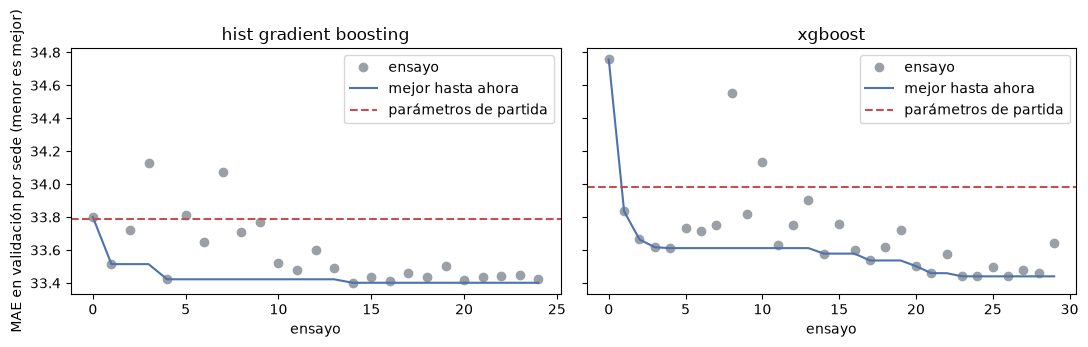

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (name, study) in zip(axes, studies.items()):
    values = [t.value for t in study.trials if t.value is not None]
    ax.plot(values, "o", color="#9aa0a6", label="ensayo")
    ax.plot(np.minimum.accumulate(values), "-", color="#4c72b0", label="mejor hasta ahora")
    ax.axhline(study.user_attrs["start_mae"], ls="--", color="#c44e52", label="parámetros de partida")
    ax.set_title(name); ax.set_xlabel("ensayo"); ax.legend()
axes[0].set_ylabel("MAE en validación por sede (menor es mejor)")
plt.tight_layout(); plt.show()

## 5. ¿Qué parámetros importaron? ¿Y los dos pendientes?

La importancia de cada parámetro dice dónde vale la pena seguir buscando. Además, el MAE medio de los ensayos según la
**pérdida** y el **umbral** `min_frequency` (pendientes de las etapas 4 y 5). Son promedios de ensayos con otros parámetros
distintos: orientan, no prueban.

In [11]:
imp = pd.DataFrame({name: pd.Series(optuna.importance.get_param_importances(study)) for name, study in studies.items()})
imp.round(3).fillna("")

,hist gradient boosting,xgboost
colsample_bytree,,0.18
l2_regularization,0.045,
learning_rate,0.387,0.046
loss,0.002,
max_depth,,0.198
max_features,0.239,
max_iter,0.016,
max_leaf_nodes,0.018,
min_child_weight,,0.413
min_frequency,0.002,0.001


In [12]:
for name, s in studies.items():
    df = s.trials_dataframe(attrs=("number", "value", "params"))
    loss_col = "params_loss" if "params_loss" in df else "params_objective"
    print(f"\n{name}: MAE medio (número de ensayos) por pérdida y umbral")
    print(df.groupby([loss_col, "params_min_frequency"])["value"].agg(["mean", "min", "count"]).round(3).to_string())


hist gradient boosting: MAE medio (número de ensayos) por pérdida y umbral
                                       mean     min  count
params_loss    params_min_frequency                       
absolute_error 0.001                 33.459  33.401     16
               0.010                 33.975  33.720      3
squared_error  0.001                 33.695  33.514      3
               0.010                 33.724  33.652      3

xgboost: MAE medio (número de ensayos) por pérdida y umbral
                                          mean     min  count
params_objective  params_min_frequency                       
reg:absoluteerror 0.001                 33.769  33.611      7
                  0.010                 34.556  34.556      1
reg:squarederror  0.001                 33.626  33.440     19
                  0.010                 33.795  33.731      3


## 6. La comprobación honesta (sedes reservadas)

Para cada finalista se entrenan **dos** modelos con toda la parte de búsqueda (parámetros de partida y optimizados) y se
evalúan en las sedes reservadas, que ninguno vio. Intervalos del 95 % remuestreando **sedes** completas.

In [13]:
preds, rows = {}, []
for name, s in studies.items():
    start_pipe = build_tuned_pipeline(name, STARTING_PARAMS[name]).fit(X_search, y_search)
    tuned_pipe = build_tuned_pipeline(name, s.best_params).fit(X_search, y_search)
    p_start, p_tuned = start_pipe.predict(X_res), tuned_pipe.predict(X_res)
    preds[name] = {"partida": p_start, "optimizados": p_tuned}
    m_start, m_tuned = regression_metrics(y_res, p_start), regression_metrics(y_res, p_tuned)
    _, s_low, s_high = bootstrap_metric_ci(y_res, p_start, X_res[GROUP_COL])
    _, t_low, t_high = bootstrap_metric_ci(y_res, p_tuned, X_res[GROUP_COL])
    diff, low, high = bootstrap_mae_difference(y_res, p_tuned, p_start, X_res[GROUP_COL])
    rows.append({
        "modelo": name,
        "MAE partida": m_start["mae"], "IC partida": f"[{s_low:.2f}; {s_high:.2f}]",
        "MAE optimizado": m_tuned["mae"], "IC optimizado": f"[{t_low:.2f}; {t_high:.2f}]",
        "diferencia (opt. − partida)": diff, "IC 95 % inferior": low, "IC 95 % superior": high,
        "RMSE partida": m_start["rmse"], "RMSE optimizado": m_tuned["rmse"],
        "R² partida": m_start["r2"], "R² optimizado": m_tuned["r2"],
        "regla 1": "optimizados" if high < 0 else "partida",
        "¿mejora real?": "sí" if high < 0 else ("no distinguible" if low <= 0 <= high else "empeora"),
    })
check = pd.DataFrame(rows).set_index("modelo")
check.round(3).T

modelo,hist gradient boosting,xgboost
MAE partida,34.041,34.072
IC partida,[33.18; 34.81],[33.20; 34.83]
MAE optimizado,33.675,33.723
IC optimizado,[32.86; 34.39],[32.87; 34.47]
diferencia (opt. − partida),-0.366,-0.349
IC 95 % inferior,-0.64,-0.57
IC 95 % superior,-0.118,-0.131
RMSE partida,42.056,42.121
RMSE optimizado,41.826,41.695
R² partida,0.351,0.349


**Cómo leer el intervalo:** si todo el intervalo está por debajo de cero, el optimizado se equivoca menos con confianza del
95 %. Si cruza el cero, la mejora **no se distingue del ruido** en estas sedes, aunque el número haya bajado.

### Regla 2: ¿cuál de los dos finalistas?

In [14]:
chosen = {name: check.loc[name, "regla 1"] for name in studies}
hgb, xgb = "hist gradient boosting", "xgboost"
p_hgb, p_xgb = preds[hgb][chosen[hgb]], preds[xgb][chosen[xgb]]
diff, low, high = bootstrap_mae_difference(y_res, p_hgb, p_xgb, X_res[GROUP_COL])
print(f"HistGradientBoosting ({chosen[hgb]}) − XGBoost ({chosen[xgb]}): MAE {diff:+.3f} puntos, IC 95 % [{low:+.3f}; {high:+.3f}]")
if low <= 0 <= high:
    final_model = hgb
    reason = "el intervalo incluye el cero (empate): se elige HistGradientBoosting por la regla de desempate"
else:
    final_model = hgb if diff < 0 else xgb
    reason = "el intervalo no incluye el cero: gana el de menor MAE"
print(f"Modelo elegido: {final_model} con parámetros {chosen[final_model]} → {reason}")
finalists_cmp = {"diferencia_hgb_menos_xgb": diff, "ic95": [low, high], "elegido": final_model, "motivo": reason}

HistGradientBoosting (optimizados) − XGBoost (optimizados): MAE -0.048 puntos, IC 95 % [-0.222; +0.119]
Modelo elegido: hist gradient boosting con parámetros optimizados → el intervalo incluye el cero (empate): se elige HistGradientBoosting por la regla de desempate


## 7. Lo que quedó registrado

Cada ensayo es una ejecución anidada bajo `optuna-<modelo>`. Contamos las ejecuciones de cada búsqueda y mostramos las
mejores, ordenadas por MAE.

In [15]:
runs = mlflow.search_runs(experiment_names=[experiment], filter_string="tags.etapa = '06_optimizacion'")
for name, s in studies.items():
    parent = s.user_attrs.get("mlflow_parent_run_id")
    children = runs[runs["tags.mlflow.parentRunId"] == parent]
    n_trials = children["tags.mlflow.runName"].str.contains("ensayo").sum()
    n_start = children["tags.mlflow.runName"].str.contains("partida").sum()
    print(f"{name}: ejecución madre {parent} · {n_trials} ensayos + {n_start} medición de partida registrados")
parents = [s.user_attrs.get("mlflow_parent_run_id") for s in studies.values()]
mine = runs[runs["tags.mlflow.parentRunId"].isin(parents)].sort_values("metrics.mae")
cols = ["tags.mlflow.runName", "metrics.mae", "metrics.mae_std", "metrics.rmse", "metrics.r2", "metrics.fit_seconds"]
mine[cols].head(8).round(3)

hist gradient boosting: ejecución madre 04e69d72e2aa45ddae3b35a620b7e357 · 25 ensayos + 1 medición de partida registrados
xgboost: ejecución madre a5272c975ae94ea3b19019fc49253351 · 30 ensayos + 1 medición de partida registrados


,tags.mlflow.runName,metrics.mae,metrics.mae_std,metrics.rmse,metrics.r2,metrics.fit_seconds
42,hist gradient boosting-ensayo-14,33.401,0.153,41.481,0.343,14.020
40,hist gradient boosting-ensayo-16,33.412,0.212,41.506,0.343,14.606
36,hist gradient boosting-ensayo-20,33.419,0.201,41.526,0.342,16.833
52,hist gradient boosting-ensayo-04,33.422,0.204,41.522,0.342,17.120
32,hist gradient boosting-ensayo-24,33.423,0.204,41.516,0.342,18.443
38,hist gradient boosting-ensayo-18,33.434,0.155,41.530,0.342,15.714
35,hist gradient boosting-ensayo-21,33.436,0.136,41.556,0.341,11.979
41,hist gradient boosting-ensayo-15,33.439,0.143,41.542,0.341,18.905


## 8. Guardar la decisión

In [16]:
best = {
    name: {
        "parametros_elegidos": "optimizados" if chosen[name] == "optimizados" else "partida",
        "params": s.best_params if chosen[name] == "optimizados" else STARTING_PARAMS[name],
        "best_params_busqueda": s.best_params,
        "cv_mae_mejor": s.best_value, "cv_mae_partida": s.user_attrs["start_mae"],
        "ensayos": len(s.trials), "minutos_busqueda": s.user_attrs["search_seconds"] / 60,
        "mlflow_parent_run_id": s.user_attrs.get("mlflow_parent_run_id"),
    }
    for name, s in studies.items()
}
best["modelo_final"] = finalists_cmp
best["tracking"] = where
best["experimento"] = experiment_label
(REPORTS_DIR / "06_best_params.json").write_text(json.dumps(best, indent=2, default=float, ensure_ascii=False), encoding="utf-8")
check.to_csv(REPORTS_DIR / "06_comprobacion.csv")
print("guardado: reports/06_best_params.json y reports/06_comprobacion.csv")

guardado: reports/06_best_params.json y reports/06_comprobacion.csv


## Entregable de esta etapa

- [x] **Un ensayo = una ejecución registrada**, con parámetros, métricas y etiquetas (sección 7).
- [x] El **presupuesto** de ensayos está escrito y se respetó (25 + 30).
- [x] Hay **sedes reservadas** que la búsqueda nunca vio (0 compartidas).
- [x] La **comprobación** (intervalo del 95 % remuestreando sedes) está hecha y la regla de decisión estaba escrita antes.
- [x] `reports/06_optimizacion.md` y `reports/06_best_params.json` completados.